# Experiment 1

In [1]:
%load_ext autoreload
%autoreload 2

## Imports

In [2]:
import os
import sys
import datetime
from collections import defaultdict
import re
from html import escape
import json
from pathlib import Path
import yaml

from dotenv import load_dotenv
import jinja2
import pandas as pd
import docker
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from playwright.async_api import async_playwright





import common

## Environmental Variables

In [3]:
load_dotenv()
s3_bucket = os.environ.get("S3_BUCKET")
print(f"S3 Bucket: {s3_bucket}")


S3 Bucket: kasbench-test-20260528-377288663341-us-east-1-an


## Constants

In [4]:
RUN = "experiment-1-run-60m-7rep-a"
SAMPLE_TRIAL = "trial0001" # Used to extract common infrastructure details
DATA_DIR = f"../data/{RUN}"
os.makedirs(DATA_DIR, exist_ok=True)
report_date = datetime.datetime.now(datetime.UTC)

RUN_DB = f"{DATA_DIR}/logs.db"
print(f"Run database is {RUN_DB}")

SLO_RT_MS = 100
SLO_FR = 0.0001

# Means from the baseline run (baseline_resource_calculations.ipynb)
SLO_RT_MS = 26.063374 * 2
SLO_FR = 0.000245 * 2

TOLERANCE = 0.20

TOTAL_CPU = 32
TOTAL_MEMORY = 64_000_000_000

TEMPLATE_DIR = "./templates"
FIGURE_DIR = "../figures"

AUTOSCALER_LOOKUP = {"hpa": "Kubernetes Horizontal Pod Autoscaler (HPA)",
    "vpa": "Kubernetes Vertical Pod Autoscaler (VPA)",
    "keda": "Kubernetes Event-Driven Autoscaler (KEDA)",
    "none": "No autoscaler (control condition)"}

TIME_SLICE_SECONDS = 30


MICROSERVICES = ["globeco-allocation-service",
    "globeco-confirmation-service",
    "globeco-execution-service",
    "globeco-fix-engine",
    "globeco-order-generation-service",
    "globeco-order-service",
    "globeco-portfolio-accounting-service",
    "globeco-portfolio-management-portal",
    "globeco-portfolio-service",
    "globeco-pricing-service",
    "globeco-security-service",
    "globeco-trade-service",
    ]

ALPHA = 0.50
BETA = 0.50
K = 5
W_MAX = 1


Run database is ../data/experiment-1-run-60m-7rep-a/logs.db


## Response Time, Failure Rate, and Roundtrip Metrics

### Compile data

In [5]:
# Download the Locust database files and load them into a single database
common.download_and_load_locust_dbs(s3_bucket, RUN, RUN_DB, DATA_DIR)


In [5]:
# Get the log as a dataframe
log_df_filename = f"{DATA_DIR}/log_df.parquet"
if os.path.exists(log_df_filename):
    log_df = pd.read_parquet(log_df_filename)
else:
    log_df = common.get_log_as_dataframe(RUN_DB)
    log_df.to_parquet(log_df_filename)

In [6]:
# Summarize by trial
trial_summary_df = common.get_trial_summary_df(log_df)

# Merge with roundtrip percentages
merged_trial_summary_df = common.merge_roundtrip_completion_percentage(None, s3_bucket, trial_summary_df, RUN)

# Summary by autoscaler
autoscaler_summary_df = common.get_autoscaler_summary(merged_trial_summary_df)


### Plots


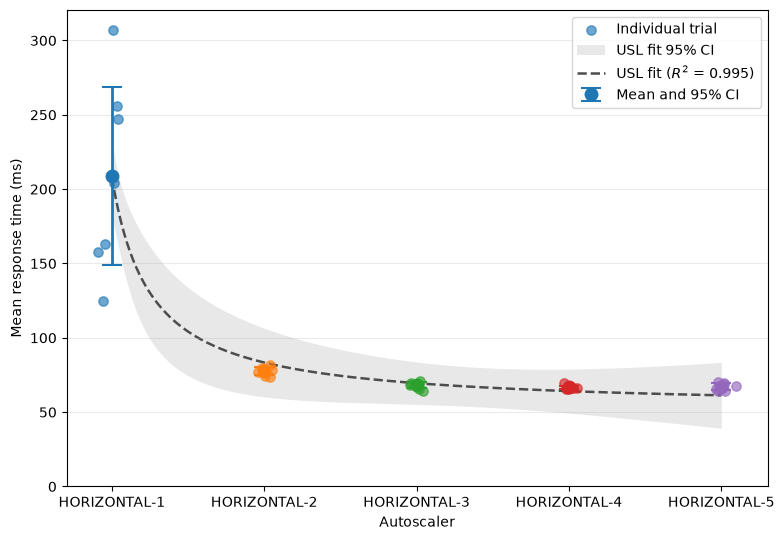

ValueError: not enough values to unpack (expected 4, got 3)

In [12]:

# Generate mean response time by autoscaler plot
fig, ax, filename, fit_stats = common.plot_mean_response_time_by_autoscaler(trial_summary_df, show=True, 
filename = "../figures/experiment_1_response_time_by_autoscaler.png",)
print(fig_stats)

# Generate failure rate by autoscaler plot
fig, ax, filename, fit_stats = common.plot_failure_rate_by_autoscaler(merged_trial_summary_df, show=True, 
filename = "../figures/experiment_1_failure_rate_by_autoscaler.png",)
print(fig_stats)

fig, ax, filename, fit_stats = common.plot_roundtrip_completion_by_autoscaler(merged_trial_summary_df, show=True, 
filename = "../figures/experiment_1_roundtrip_completion_by_autoscaler.png",)
print(fig_stats)
